<a href="https://colab.research.google.com/github/George7531/Portfolio_Management/blob/main/george_report_pm_gp1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 3: Simulation vs Optimization




I lay bare the conditions and the objective here:

we have to simulate many times and find the number of times we have to run the simulation to get portfolio weights that would closely match those weights obtained by typical numerical optimization.

The conditions to meet are:
1. We have to select 5 assets out of the 10 given.
2. Weights have to sum to 1.
3. There are no short sales.

I'm going to select Tesla, Walmart, Google, Meta, Bank of America.

This is their expected annual returns and Annual covariance matrix:

### Expected Annual Returns

| Asset | Expected Annual Return |
| :--- | :--- |
| **TSLA** | 0.458054 |
| **WMT** | 0.344429 |
| **BAC** | 0.341716 |
| **GOOG** | 0.324126 |
| **META** | 0.506922 |



### Annual Covariance Matrix

| Asset | TSLA | WMT | BAC | GOOG | META |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **TSLA** | 0.395726 | 0.034555 | 0.056568 | 0.071297 | 0.076814 |
| **WMT** | 0.034555 | 0.044671 | 0.014185 | 0.010827 | 0.019652 |
| **BAC** | 0.056568 | 0.014185 | 0.065493 | 0.019061 | 0.026793 |
| **GOOG** | 0.071297 | 0.010827 | 0.019061 | 0.087397 | 0.050470 |
| **META** | 0.076814 | 0.019652 | 0.026793 | 0.050470 | 0.130926 |



This is the optimizer solution under the 2 constraint sets which will serve as our baseline to compare our simulated results against.


### Portfolio Optimization Results Under Constraints

| Ticker | Constraint Set 1 | Constraint Set 2 |
| :--- | :--- | :--- |
| TSLA | 0.000000 | 0.000000 |
| WMT | 0.455321 | 0.300000 |
| BAC | 0.215704 | 0.300000 |
| GOOG | 0.019817 | 0.100000 |
| META | 0.309158 | 0.300000 |
| **Weight Sum** | 1.000000 | 1.000000 |
| **Expected Annual Return** | 0.393678 | 0.390333 |
| **Annualized Volatility** | 0.194231 | 0.195722 |
| **Sharpe Ratio** | 2.026853 | 1.994325 |


under these constraints we allocate no capital to Tesla, and Walmart is the one that got the highest 45.53% under constraint 1 which is about weight summing to 1 and independent of the second constraint under which assets get no greater than 30% weight. Another jarring thing note here is under both of these constraints Google received second most least weights. Under constraint expected returns dropped slightly and volatility increased a bit too.

### simulated results:

Now lets see how many iterations it takes for our simulated results to match this optimizer result:


This is how I set up my simulator:

The number of simulations to run are:
$ N= [100, 1000, 10000, 100000] $

As we increase the number of simulations the chance empirical calculation to match the numerical optimization would increase: the law of large numbers.

our simulation function is going to look like this, a rough plan:

* The function is going to draw weights from a Dirichlet distribution ensuring all asset weights are non-negative and sum to 100%,  $\sum w_i = 1$.

* Have an empty portfolio container.
* Determine how many candidates (weights of assets) to generate per iteration, let's call it batch_size, the default size is going to be 1000 samples.
* Supply number of assets and batch size as attributes to dirichlet distribution function and get the weights.
* Have a filter to filter out weights that are outside the bounds of lower and upper: (candidates >= lower_bounds).all(axis=1) & (
    candidates <= upper_bounds).all(axis=1)
* As long as the porfolio size is less than the n_simulations we are going to run this test iteratively.
* Return the simulated number of portfolios.
* then we compute the expected returns and annual volality to compare.
### Monte Carlo Simulation vs. Optimal Utility Comparison

| Index | Constraint Set | Simulations | Best Simulated Utility | Optimal Utility | Utility Gap | Maximum Weight Difference | Mean Weight Difference |
| :---: | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **0** | Constraint_Set_1 | 100 | 0.274506 | 0.278080 | 0.003574 | 0.089230 | 0.053652 |
| **1** | Constraint_Set_1 | 1,000 | 0.276785 | 0.278080 | 0.001295 | 0.045772 | 0.029272 |
| **2** | Constraint_Set_1 | 10,000 | 0.276834 | 0.278080 | 0.001246 | 0.066381 | 0.026552 |
| **3** | Constraint_Set_1 | 100,000 | 0.277559 | 0.278080 | 0.000521 | 0.044762 | 0.018915 |
| **4** | Constraint_Set_2 | 100 | 0.261597 | 0.272954 | 0.011357 | 0.094689 | 0.053111 |
| **5** | Constraint_Set_2 | 1,000 | 0.269177 | 0.272954 | 0.003776 | 0.045743 | 0.019710 |
| **6** | Constraint_Set_2 | 10,000 | 0.270860 | 0.272954 | 0.002093 | 0.033308 | 0.013323 |
| **7** | Constraint_Set_2 | 100,000 | 0.272358 | 0.272954 | 0.000596 | 0.013513 | 0.005405 |



- for constraint set 1, At 100 simulations, the utility gap is approximately 0.00357.
- At 1,000 simulations, it falls to 0.00130.
- At 10,000 simulations, it is  0.00125.
- At 100,000 simulations, it is close to 0.00052.
The largest improvement occurs between 100 and 1,000 simulations. The improvement between 1,000 and 10,000 is relatively small, followed by another improvement at 100,000.

for constraint 2
- At 100 simulations, the utility gap is approximately 0.01136, it falls to approximately 0.00378 at 1000, to 0.00209 at 10,000 and to 0.00060 at 100k. Constraint Set 2 shows a consistent reduction in the utility gap as the simulation count increases.


### plots:



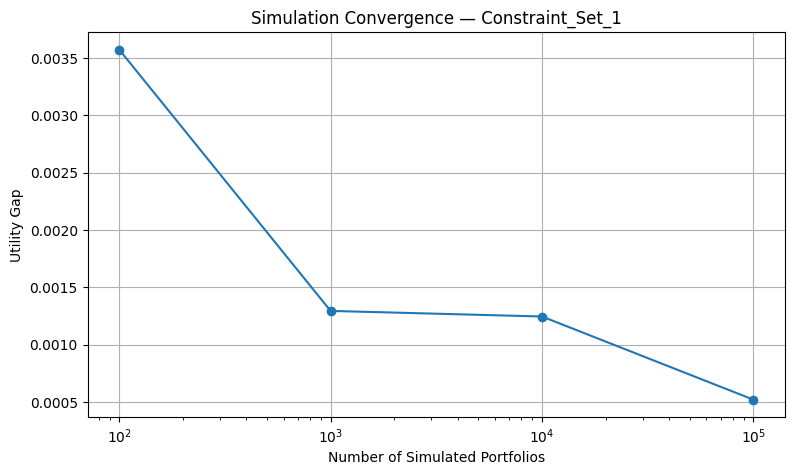

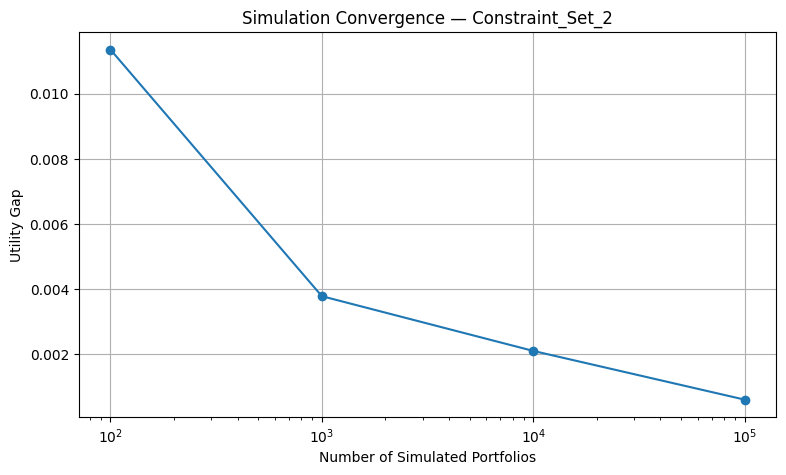

In [1]:
from IPython.display import Image, display
display(Image('/content/part8_pic1.png'))
display(Image('/content/part8_pic2.png'))


Looks like it takes about a 100k simulated portfolios to close the gap between the answers between that obtained using optimizer vs that we got using simulator.

### Numerical Optimization vs. Best Random Simulation

#### Constraint Set 1

| Asset | Numerical Optimization | Best Random Simulation | Absolute Difference |
| :--- | :---: | :---: | :---: |
| **TSLA** | 0.000000 | 0.002525 | 0.002525 |
| **WMT** | 0.455321 | 0.422817 | 0.032503 |
| **BAC** | 0.215704 | 0.260467 | 0.044762 |
| **GOOG** | 0.019817 | 0.015362 | 0.004455 |
| **META** | 0.309158 | 0.298828 | 0.010330 |

| Metric | Value |
| :--- | :---: |
| **Maximum Weight Difference** | 0.044762 |
| **Mean Weight Difference** | 0.018915 |

---

#### Constraint Set 2

| Asset | Numerical Optimization | Best Random Simulation | Absolute Difference |
| :--- | :---: | :---: | :---: |
| **TSLA** | 0.000000 | 0.013513 | 0.013513 |
| **WMT** | 0.300000 | 0.298419 | 0.001581 |
| **BAC** | 0.300000 | 0.295519 | 0.004481 |
| **GOOG** | 0.100000 | 0.093468 | 0.006532 |
| **META** | 0.300000 | 0.299081 | 0.000919 |

| Metric | Value |
| :--- | :---: |
| **Maximum Weight Difference** | 0.013513 |
| **Mean Weight Difference** | 0.005405 |



We can discern that 100,000 simulations appear sufficient to obtain very close weights under Constraint Set 2. Under Constraint Set 1, 100,000 simulations improve the result considerably, but the weights are not yet as close since its mean difference 0.018915 is relatively higher.


for constraint 1:
The largest improvement occurs between 100 and 1,000 simulations. The improvement between 1,000 and 10,000 is relatively small, followed by another improvement at 100,000 making the improvement trajectory look like it might increase further if we increase the simulation.

constraint 2's behaviour:
Constraint Set 2 shows a steady reduction in the utility gap as the simulation count got closer to the optimizer's value iteration by iteration.
